# **Trabajo Práctico 1 - Mineria de Datos**

## *Integrantes: Aldana Desiré Sanchez y Gaston Rinaldi*

>>>>>> Año 2026



In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.cluster.hierarchy as sch
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.manifold import Isomap, TSNE
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score

The `species` column is currently of `object` (string) type. Converting it to a `category` dtype is a good practice for memory efficiency and potentially faster operations, as there are a limited number of penguin species.

In [ ]:
# Configuración visual
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (8, 5)

# ==========================================
# 1. Carga, EDA, Limpieza y Estandarización
# ==========================================

# Cargar dataset (asegurarse de tener penguins_size.csv en la misma carpeta)
df = pd.read_csv("penguins_size.csv", sep=';')

# Eliminamos las columnas vacias
df = df.loc[:, ~df.columns.str.contains('^Unnamed')]

# Exploración rápida
print(df.info())
print(df.isnull().sum())

# Tratamiento de valores nulos (imputación por mediana para numéricas, moda para categóricas)
num_cols = ['Longitud Culmen (mm)', 'Profundidad Culmen (mm)', 'Longitud Aleta (mm)', 'Masa corporal (g)']
for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

df['Sexo'] = df['Sexo'].fillna(df['Sexo'].mode()[0])
# Corregir posible categoría errónea en 'sex' (algunos datasets tienen '.')
df = df[df['Sexo'] != '.']

# Guardar la variable objetivo
y = df['Especie']

# Codificación de variables categóricas secundarias (ej. island, sex) si se usan para features
# O selección estricta de variables numéricas para reducción de dimensión / clustering:
X_num = df[num_cols].copy()

# Normalización / Estandarización
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_num)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 347 entries, 0 to 346
Data columns (total 6 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Especie                  347 non-null    object 
 1   Longitud Culmen (mm)     345 non-null    float64
 2   Profundidad Culmen (mm)  345 non-null    float64
 3   Longitud Aleta (mm)      345 non-null    float64
 4   Masa corporal (g)        345 non-null    float64
 5   Sexo                     337 non-null    object 
dtypes: float64(4), object(2)
memory usage: 16.4+ KB
None
Especie                     0
Longitud Culmen (mm)        2
Profundidad Culmen (mm)     2
Longitud Aleta (mm)         2
Masa corporal (g)           2
Sexo                       10
dtype: int64


### Exploratory Data Analysis (EDA)

Hacemos el analisis exploratorio para entender las caracteristicas del dataset, las distribuciones y la posible relacion entre variables.


In [ ]:
df.describe()

,Longitud Culmen (mm),Profundidad Culmen (mm),Longitud Aleta (mm),Masa corporal (g)
count,346.000000,346.000000,346.000000,346.000000
mean,43.945376,17.160116,200.875723,4201.156069
std,5.502078,1.962747,14.062145,804.332990
min,32.100000,13.100000,172.000000,2700.000000
25%,39.225000,15.600000,190.000000,3550.000000
50%,44.400000,17.300000,197.000000,4050.000000
75%,48.500000,18.675000,213.000000,4750.000000
max,59.600000,21.500000,231.000000,6300.000000


Vamos a visualizar las relaciones entre los features numericos coloreado por especies usando scatterplots.

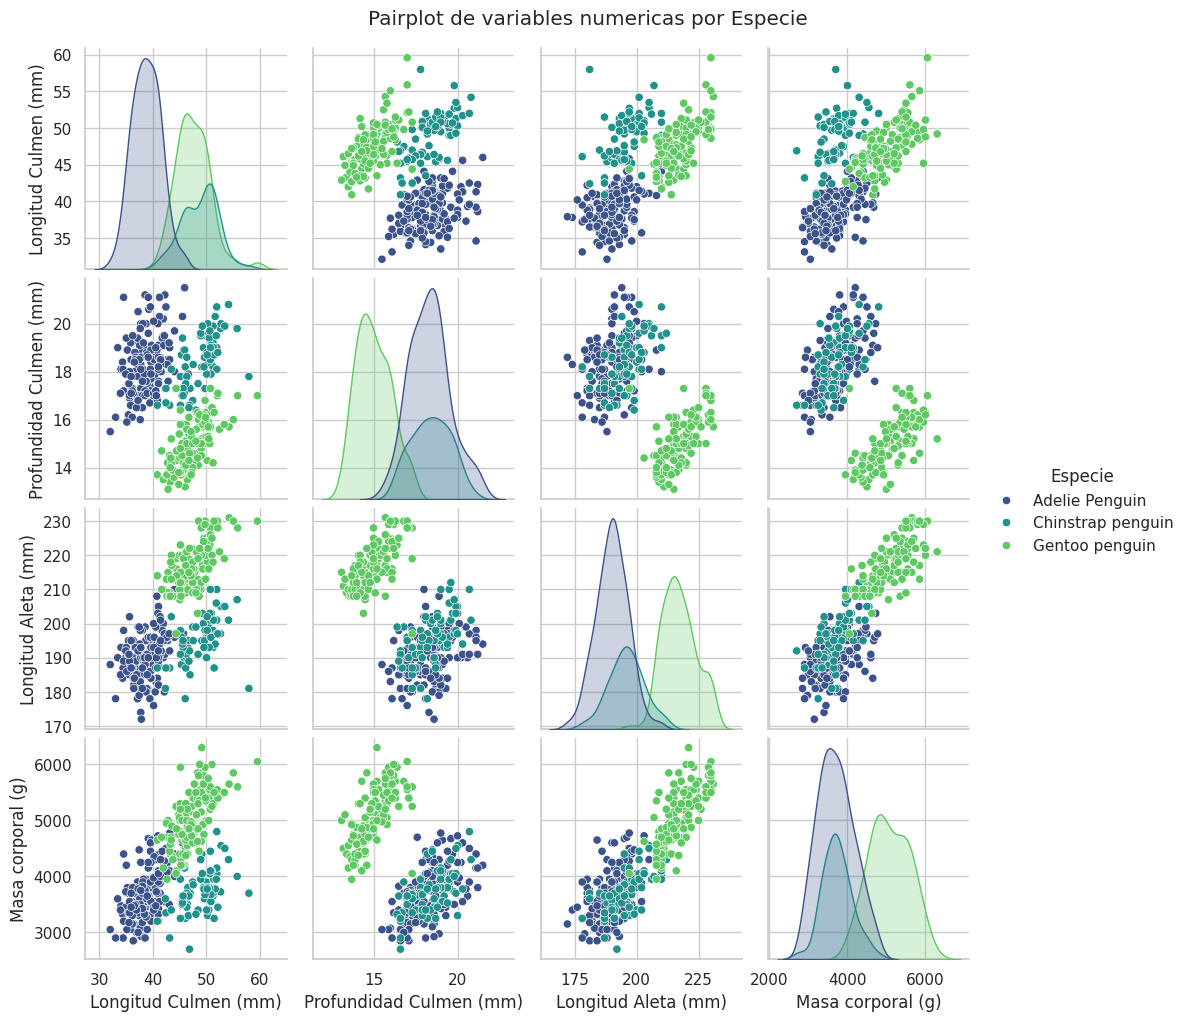

In [ ]:
# Scatterplots de variables numericas, coloreados por especie

# Identificamos columnas numericas (expluimos 'Especie')
numerical_cols = ['Longitud Culmen (mm)', 'Profundidad Culmen (mm)', 'Longitud Aleta (mm)', 'Masa corporal (g)']

# Pairplot de relaciones entre variables
sns.pairplot(df, hue='Especie', vars=numerical_cols, palette='viridis')
plt.suptitle('Pairplot de variables numericas por Especie', y=1.02) # Ajuste de posicion de titulo
plt.show()

>> **Pairplot de Variables Numéricas por Especie**

>>> Este gráfico de dispersión por pares (pairplot) muestra las relaciones bivariadas entre todas las características numéricas del dataset, coloreadas por la especie de pingüino. Podemos observar cómo las diferentes especies tienden a formar agrupaciones distintas en varias de las combinaciones de características, lo que sugiere una buena separabilidad entre ellas. Por ejemplo, `Longitud Culmen (mm)` muestra claras diferencias entre las especies.

>>> En los graficos que se encuentran en la diagonal vemos la distribucion de cada variable por especie.

In [ ]:
# Convertimos 'Especie' en categoría
df['Especie'] = df['Especie'].astype('category')
df['Sexo'] = df['Sexo'].astype('category')

# Verificamos cambios
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 346 entries, 0 to 346
Data columns (total 6 columns):
 #   Column                   Non-Null Count  Dtype   
---  ------                   --------------  -----   
 0   Especie                  346 non-null    category
 1   Longitud Culmen (mm)     346 non-null    float64 
 2   Profundidad Culmen (mm)  346 non-null    float64 
 3   Longitud Aleta (mm)      346 non-null    float64 
 4   Masa corporal (g)        346 non-null    float64 
 5   Sexo                     346 non-null    category
dtypes: category(2), float64(4)
memory usage: 14.4 KB


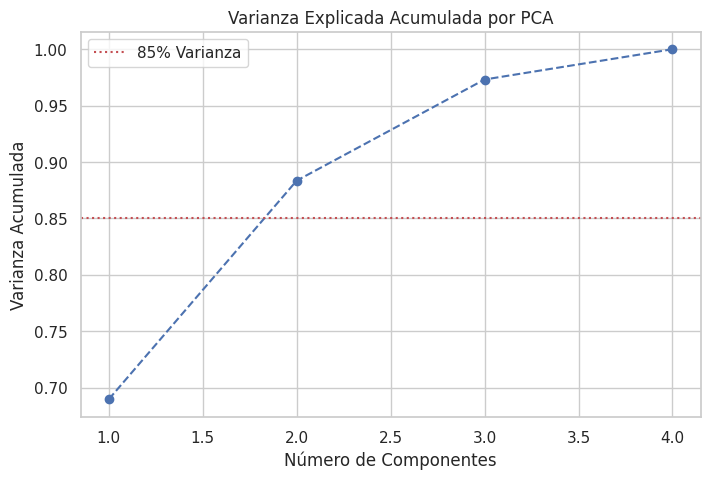

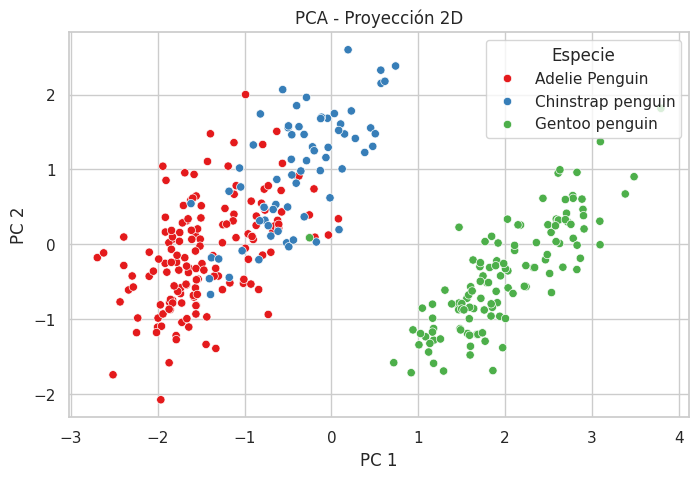

In [ ]:
# ==========================================
# 2. PCA (Análisis de Componentes Principales)
# ==========================================

pca_full = PCA().fit(X_scaled)
var_exp = pca_full.explained_variance_ratio_
var_cum = np.cumsum(var_exp)

# Gráfico de Varianza Acumulada
plt.figure()
plt.plot(range(1, len(var_cum) + 1), var_cum, marker='o', linestyle='--')
plt.axhline(y=0.85, color='r', linestyle=':', label='85% Varianza')
plt.title('Varianza Explicada Acumulada por PCA')
plt.xlabel('Número de Componentes')
plt.ylabel('Varianza Acumulada')
plt.legend()
plt.show()

# Aplicar PCA con 2D y 3D para graficar
pca_2d = PCA(n_components=2).fit_transform(X_scaled)

plt.figure()
sns.scatterplot(x=pca_2d[:, 0], y=pca_2d[:, 1], hue=y, palette='Set1')
plt.title('PCA - Proyección 2D')
plt.xlabel('PC 1')
plt.ylabel('PC 2')
plt.show()

# Criterios evaluados:
# Criterio 1: Porcentaje de varianza acumulada (ej. > 80-85%).
# Criterio 2: Regla de Kaiser (Eigenvalores > 1 / Varianza explicada por encima de la media).
# Criterio 3: Gráfico de codo (Scree plot).

>>**Varianza Explicada Acumulada por PCA**

>>>Este gráfico muestra la varianza acumulada explicada por cada componente principal. La línea horizontal roja indica el 85% de la varianza. Observamos que con dos componentes principales se logra capturar una gran parte de la variabilidad original de los datos, lo que justifica la reducción de dimensionalidad a 2D para visualización.

>>**PCA - Proyección 2D**

>>>Esta visualización muestra los datos proyectados en los dos primeros componentes principales. Se puede observar una separación entre las especies de pingüinos, lo que indica que PCA es efectivo para diferenciar los grupos basándose en las características numéricas.

### Criterio 2: Regla de Kaiser (Eigenvalores > 1)

In [ ]:
eigenvalues = pca_full.explained_variance_
num_components_kaiser = sum(eigenvalues > 1)
print(f"Número de componentes según la Regla de Kaiser (eigenvalores > 1): {num_components_kaiser}")

Número de componentes según la Regla de Kaiser (eigenvalores > 1): 1


Solo un componente tiene un eigenvalue mayor a 1.

### Criterio 3: Gráfico de Codo (Scree Plot)

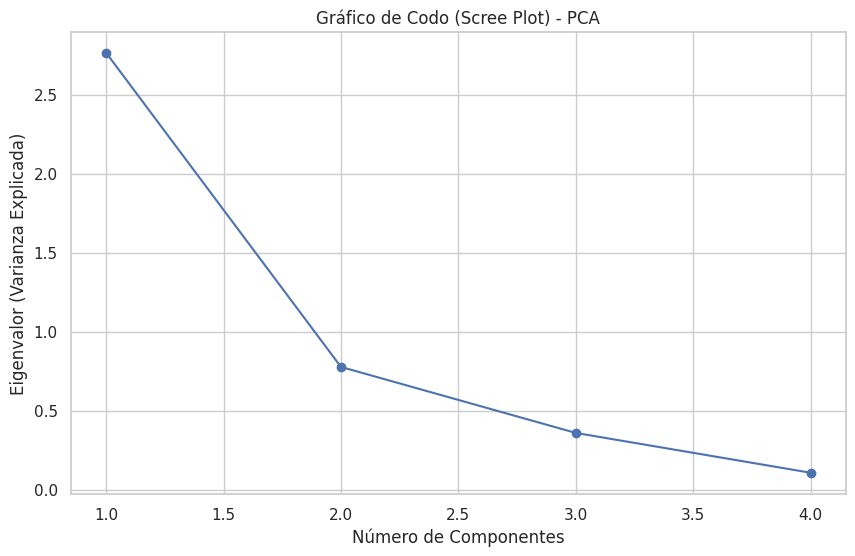

In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(range(1, len(eigenvalues) + 1), eigenvalues, marker='o', linestyle='-')
plt.title('Gráfico de Codo (Scree Plot) - PCA')
plt.xlabel('Número de Componentes')
plt.ylabel('Eigenvalor (Varianza Explicada)')
plt.grid(True)
plt.show()

>>**Gráfico de Codo (Scree Plot) - PCA**

>>>El Scree Plot muestra el valor propio (eigenvalue) de cada componente principal. Se busca un 'codo' o punto de inflexión en la curva, donde la pendiente disminuye bruscamente. Este punto sugiere el número óptimo de componentes a retener, ya que los componentes posteriores aportan significativamente menos información. En este caso, el codo podría interpretarse en el segundo componente.

Segun la Regla del Codo(Scree) y la Proporción de Varianza Acumulada, nos quedamos con los 2 primeros componentes.
  

/usr/local/lib/python3.13/dist-packages/sklearn/manifold/_isomap.py:384: UserWarning: The number of connected components of the neighbors graph is 2 > 1. Completing the graph to fit Isomap might be slow. Increase the number of neighbors to avoid this issue.
  self._fit_transform(X)
/usr/local/lib/python3.13/dist-packages/scipy/sparse/_index.py:168: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil and dok are more efficient.
  self._set_intXint(row, col, x.flat[0])


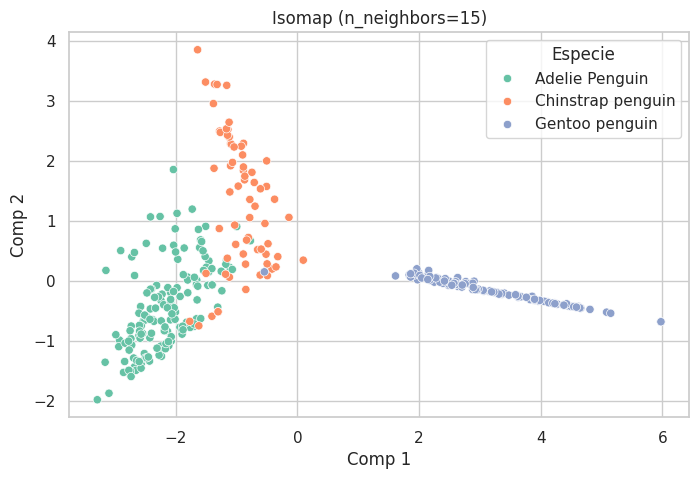

/usr/local/lib/python3.13/dist-packages/sklearn/manifold/_isomap.py:384: UserWarning: The number of connected components of the neighbors graph is 2 > 1. Completing the graph to fit Isomap might be slow. Increase the number of neighbors to avoid this issue.
  self._fit_transform(X)
/usr/local/lib/python3.13/dist-packages/scipy/sparse/_index.py:168: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil and dok are more efficient.
  self._set_intXint(row, col, x.flat[0])


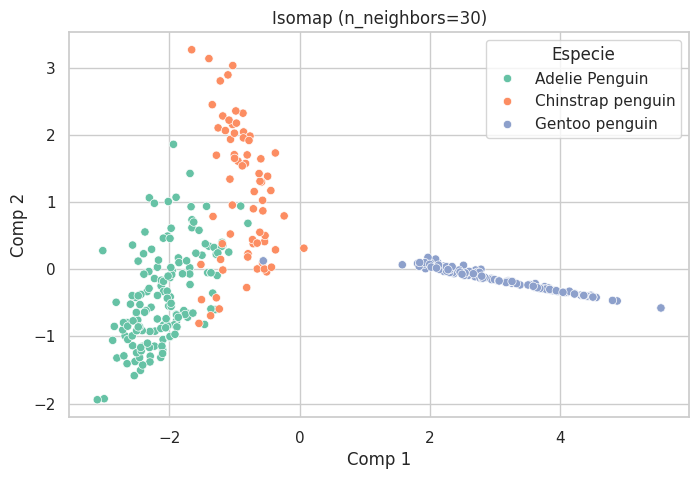

/usr/local/lib/python3.13/dist-packages/sklearn/manifold/_isomap.py:384: UserWarning: The number of connected components of the neighbors graph is 2 > 1. Completing the graph to fit Isomap might be slow. Increase the number of neighbors to avoid this issue.
  self._fit_transform(X)
/usr/local/lib/python3.13/dist-packages/scipy/sparse/_index.py:168: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil and dok are more efficient.
  self._set_intXint(row, col, x.flat[0])


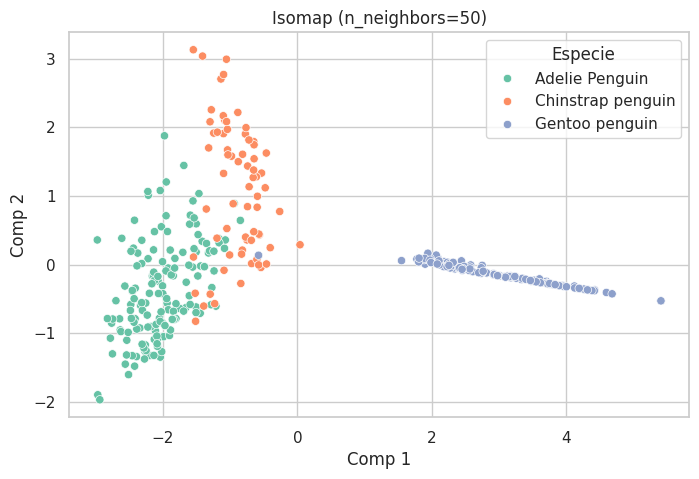

In [ ]:
# ==========================================
# 3. Isomap
# ==========================================

for n_neighbors in [15, 30, 50]: # Valores incrementales para vecinos
    iso = Isomap(n_neighbors=n_neighbors, n_components=2)
    X_iso = iso.fit_transform(X_scaled)

    plt.figure()
    sns.scatterplot(x=X_iso[:, 0], y=X_iso[:, 1], hue=y, palette='Set2')
    plt.title(f'Isomap (n_neighbors={n_neighbors})')
    plt.xlabel('Comp 1')
    plt.ylabel('Comp 2')
    plt.show()

>>**Proyecciones 2D para Diferentes `n_neighbors`**

>>>Estos gráficos muestran las proyecciones 2D obtenidas con Isomap para diferentes valores del parámetro `n_neighbors`. Se observa que Isomap logra separar las especies, más efectivamente a 1 de ellas en comparacion con las otras 2, similar a PCA. El parámetro `n_neighbors` influye en la conectividad del grafo subyacente y, por ende, en la topología capturada. Valores más grandes de `n_neighbors` (como 30 o 50) pueden suavizar el mapa y potencialmente evitar advertencias sobre componentes desconectados, como las observadas en algunas ejecuciones.



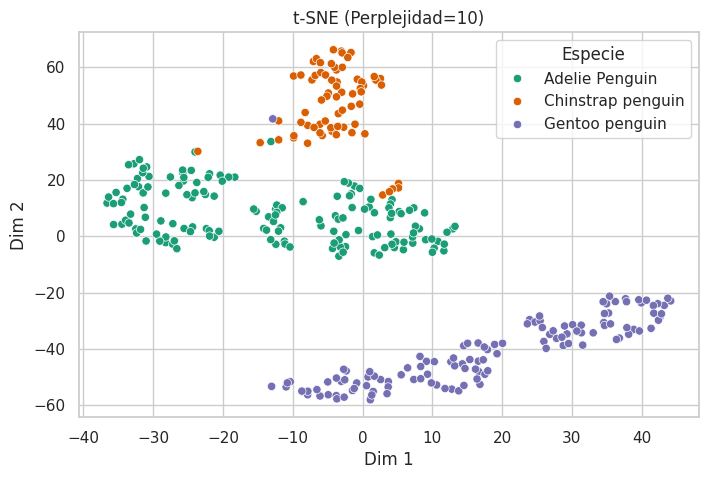

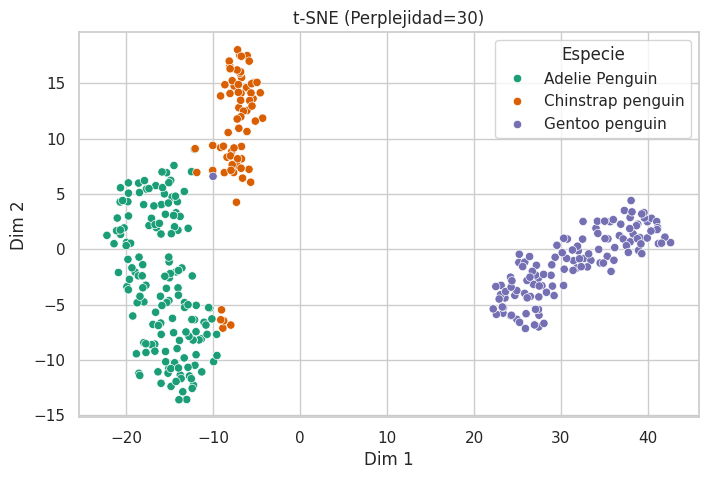

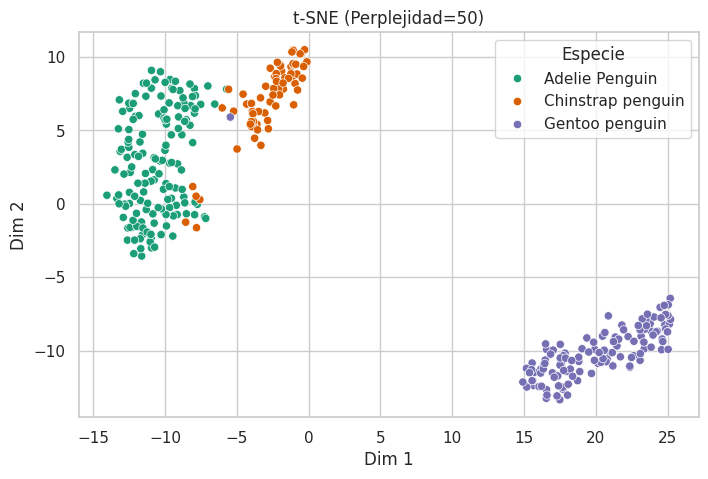

In [ ]:
# ==========================================
# 4. t-SNE
# ==========================================

for perplexity in [10, 30, 50]: # vamos probando con distintos valores de perplexity
    tsne = TSNE(n_components=2, perplexity=perplexity, max_iter=1000, random_state=42)
    X_tsne = tsne.fit_transform(X_scaled)

    plt.figure()
    sns.scatterplot(x=X_tsne[:, 0], y=X_tsne[:, 1], hue=y, palette='Dark2')
    plt.title(f't-SNE (Perplejidad={perplexity})')
    plt.xlabel('Dim 1')
    plt.ylabel('Dim 2')
    plt.show()

>>**t-SNE - Proyecciones 2D para diferentes perplejidades**

>>>Estos gráficos de t-SNE ilustran cómo el parámetro `perplejidad` afecta la visualización de las agrupaciones. El mismo se puede entender como una conjetura sobre el número de vecinos cercanos que cada punto de datos tiene.
*   Con `Perplejidad=10`, las agrupaciones se distinguen entre sí pero son menos compactas y más dispersas.
*   Con `Perplejidad=30`, las tres especies se presentan con agrupaciones claras y bien separadas, lo que sugiere que este valor es adecuado para el dataset.
*   Con `Perplejidad=50`, las agrupaciones siguen siendo claras, pero en algunos casos, valores muy altos pueden fusionar estructuras que deberían estar separadas.

>>>En este caso, 30 parece ser un buen compromiso para revelar la estructura de los datos.

### Visualización de t-SNE variando el número de iteraciones

Visualizando t-SNE variando max_iter (perplejidad fija):
---------------------------------------------------


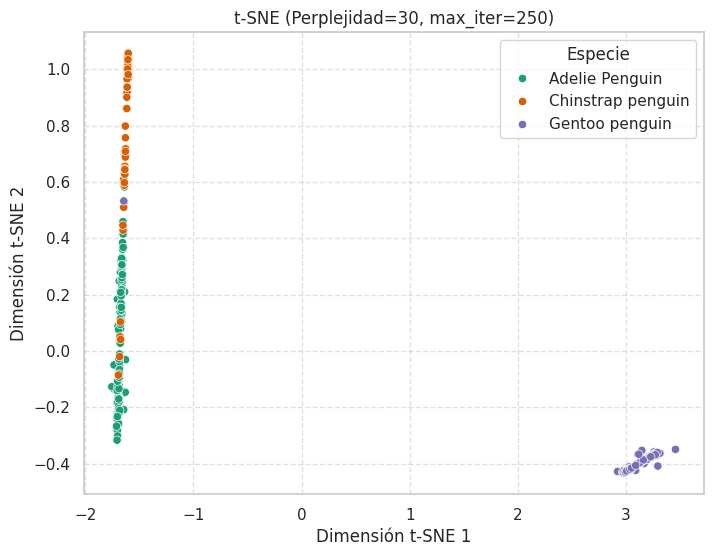

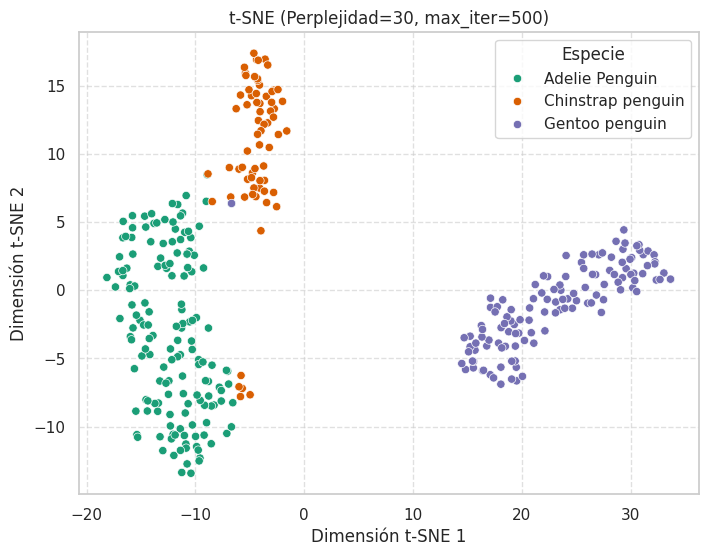

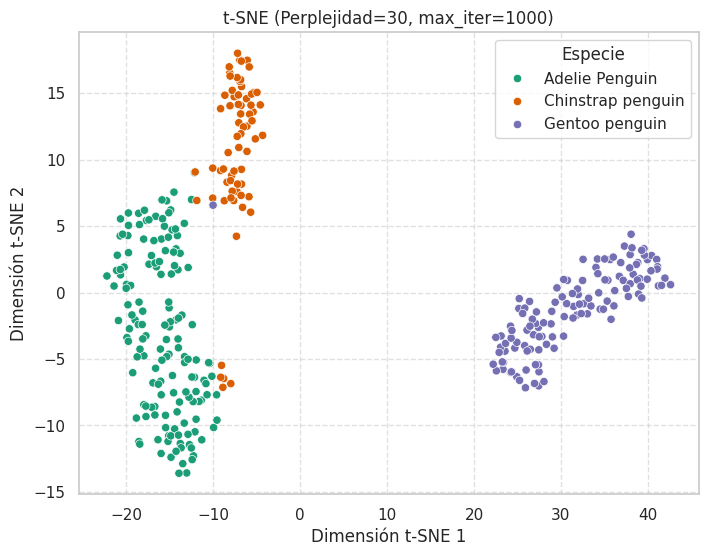

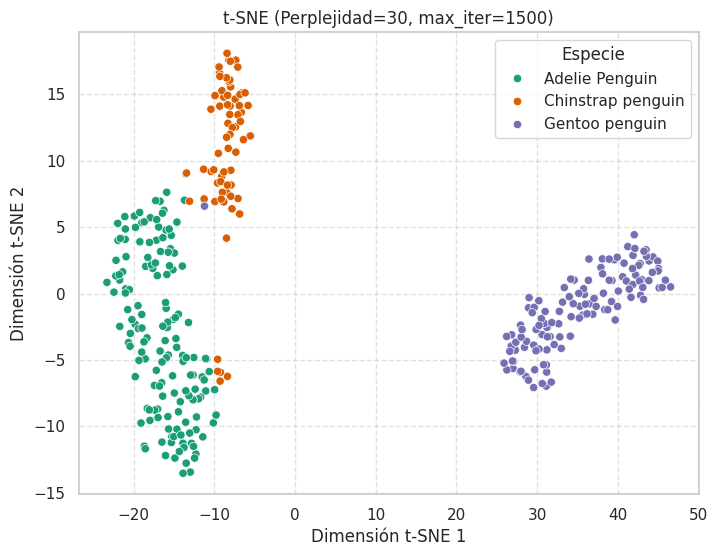


Visualizaciones completadas.


In [ ]:
print("Visualizando t-SNE variando max_iter (perplejidad fija):")
print("---------------------------------------------------")

fixed_perplexity = 30 # Usaremos la misma perplejidad fija
iteration_values = [250, 500, 1000, 1500] # Valores a probar para max_iter (modificado de [100, 250, 1000, 1500])

for max_iter_val in iteration_values:
    tsne = TSNE(n_components=2, perplexity=fixed_perplexity, max_iter=max_iter_val, random_state=42, learning_rate='auto')
    X_tsne_reduced = tsne.fit_transform(X_scaled)

    plt.figure(figsize=(8, 6))
    sns.scatterplot(x=X_tsne_reduced[:, 0], y=X_tsne_reduced[:, 1], hue=y, palette='Dark2')
    plt.title(f't-SNE (Perplejidad={fixed_perplexity}, max_iter={max_iter_val})')
    plt.xlabel('Dimensión t-SNE 1')
    plt.ylabel('Dimensión t-SNE 2')
    plt.legend(title='Especie')
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.show()

print("\nVisualizaciones completadas.")

>>**t-SNE - Proyecciones 2D para diferentes iteraciones**

>>>Estos gráficos muestran el impacto del número de iteraciones (`max_iter`) en la convergencia de t-SNE. Un número insuficiente de iteraciones puede resultar en una visualización incompleta o incorrecta, donde las agrupaciones no están bien formadas o separadas.
Para comparar las diferencias en las iteraciones, dejamos fijo el numero de perplejidad en 30 como identificamos anteriormente.
*   Para `max_iter=250`, las agrupaciones empiezan a definirse, pero no son tan compactas.
*   A medida que `max_iter` aumenta (500, 1000, 1500), las agrupaciones se vuelven más densas y las separaciones entre las especies son más nítidas, indicando una mejor convergencia del algoritmo. Esto confirma que un `max_iter` suficiente es crucial para obtener una representación precisa de la estructura de alta dimensionalidad.

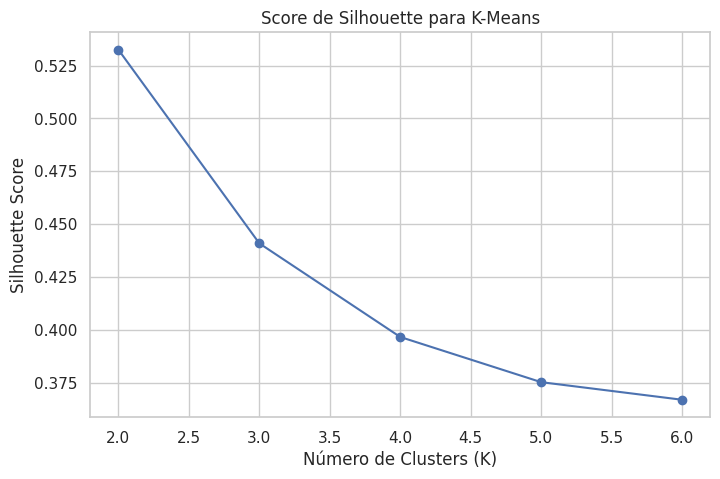

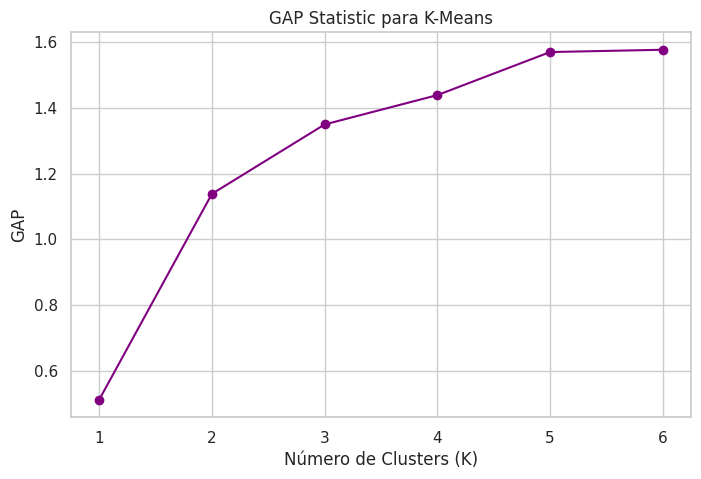

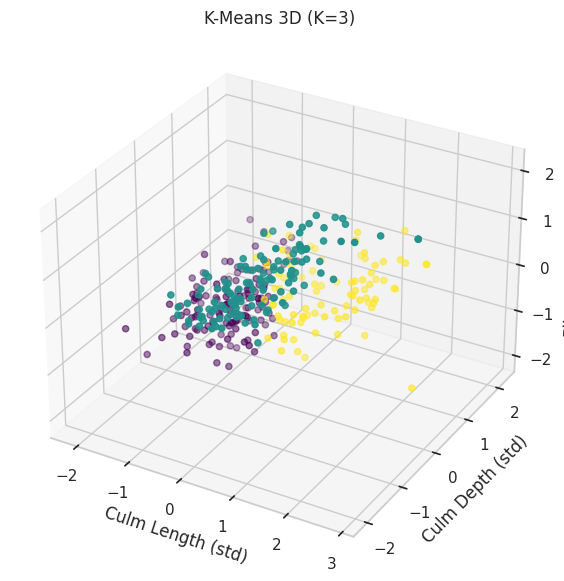

In [ ]:
# ==========================================
# 5. K-Means (Silhouette & Gap Statistic)
# ==========================================

# Silhouette Score para K entre 2 y 6
silhouette_scores = []
K_range = range(2, 7)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_scaled)
    score = silhouette_score(X_scaled, kmeans.labels_)
    silhouette_scores.append(score)

plt.figure()
plt.plot(K_range, silhouette_scores, marker='o')
plt.title('Score de Silhouette para K-Means')
plt.xlabel('Número de Clusters (K)')
plt.ylabel('Silhouette Score')
plt.show()

# Función simplificada para calcular GAP Statistic
def gap_statistic(X, k_max=6, n_bootstraps=10):
    gaps = []
    for k in range(1, k_max + 1):
        # Cluster real
        km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X)
        disp_real = km.inertia_

        # Datasets de referencia nulos
        disp_null = []
        for _ in range(n_bootstraps):
            random_data = np.random.uniform(X.min(axis=0), X.max(axis=0), X.shape)
            km_null = KMeans(n_clusters=k, random_state=42, n_init=10).fit(random_data)
            disp_null.append(km_null.inertia_)

        gap = np.mean(np.log(disp_null)) - np.log(disp_real)
        gaps.append(gap)
    return gaps

gaps_km = gap_statistic(X_scaled, k_max=6)

plt.figure()
plt.plot(range(1, 7), gaps_km, marker='o', color='purple')
plt.title('GAP Statistic para K-Means')
plt.xlabel('Número de Clusters (K)')
plt.ylabel('GAP')
plt.show()

# Gráfico 3D de K-Means con el K óptimo (ej. K=3)
optimal_k = 3
km_opt = KMeans(n_clusters=optimal_k, random_state=42, n_init=10).fit(X_scaled)

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection='3d')
scatter = ax.scatter(X_scaled[:, 0], X_scaled[:, 1], X_scaled[:, 2], c=km_opt.labels_, cmap='viridis')
ax.set_xlabel('Culm Length (std)')
ax.set_ylabel('Culm Depth (std)')
ax.set_zlabel('Flipper Length (std)')
plt.title(f'K-Means 3D (K={optimal_k})')
fig.subplots_adjust(right=0.85)
plt.show()

>>**Score de Silhouette para K-Means**

>>>Este gráfico muestra el Silhouette Score para diferentes números de clusters (K) en el algoritmo K-Means. El Silhouette Score mide qué tan similar es un objeto a su propio cluster en comparación con otros clusters. Un valor más alto indica una mejor separación y coherencia de los clusters. Aquí, el pico más alto del score sugiere el número óptimo de clusters: 2.

>>**GAP Statistic para K-Means**

>>>El gráfico del GAP Statistic compara la dispersión dentro del cluster de los datos reales con la de un conjunto de datos de referencia aleatorio. Un valor GAP más alto indica que la estructura de clustering es más fuerte que la esperada al azar. Aquí el GAP crece de forma continua con K (≈0.53, 1.13, 1.35, 1.45, 1.56, 1.61 para K=1 a 6), por lo que no tiene un máximo que marque un K óptimo. El mayor aporte se produce al pasar de K=1 a K=2 (+0.60), y desde ahí las ganancias son cada vez menores (+0.22, +0.10, ...). Tomando ese punto de inflexión (codo), el número de clusters es 2, coincidiendo con el Score de Silhouette.

>>**K-Means 3D Plot**

>>>Este gráfico de dispersión 3D visualiza los datos en función de las tres primeras características escaladas, coloreados según las etiquetas de cluster asignadas por K-Means con el `K` óptimo (o un K elegido para visualización). Permite observar la distribución espacial de los clusters y cómo se agrupan los puntos en un espacio tridimensional. En este caso, aunque el óptimo de K es 2, se visualiza con K=3 para intentar reflejar las especies, mostrando cómo se distribuyen los grupos.

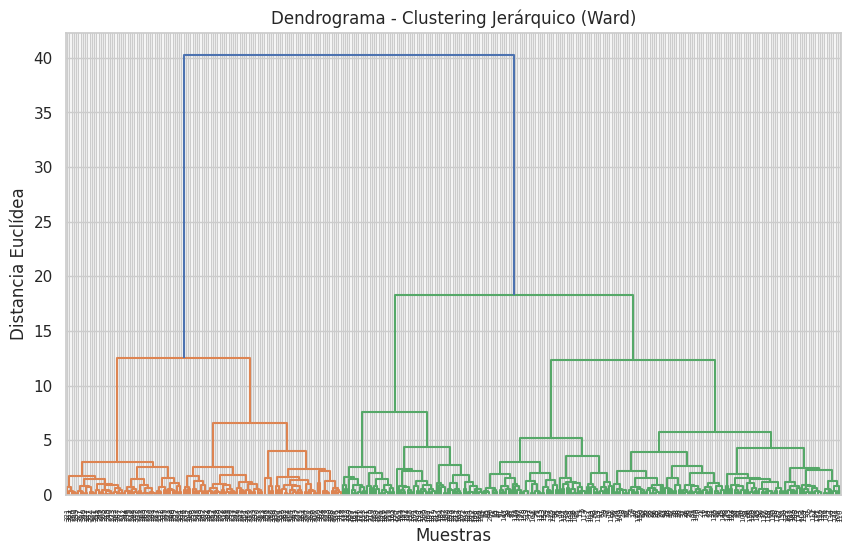

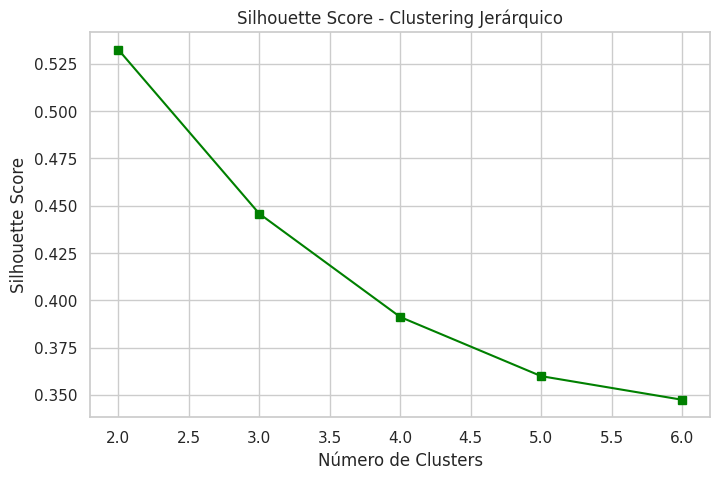

In [ ]:
# ==========================================
# 6. Clustering Jerárquico
# ==========================================

# Dendrograma
plt.figure(figsize=(10, 6))
dendrogram = sch.dendrogram(sch.linkage(X_scaled, method='ward'))
plt.title('Dendrograma - Clustering Jerárquico (Ward)')
plt.xlabel('Muestras')
plt.ylabel('Distancia Euclídea')
plt.show()

# Evaluación de K óptimo en Jerárquico mediante Silhouette
sil_jer = []
for k in range(2, 7):
    hc = AgglomerativeClustering(n_clusters=k, linkage='ward')
    labels = hc.fit_predict(X_scaled)
    sil_jer.append(silhouette_score(X_scaled, labels))

plt.figure()
plt.plot(range(2, 7), sil_jer, marker='s', color='green')
plt.title('Silhouette Score - Clustering Jerárquico')
plt.xlabel('Número de Clusters')
plt.ylabel('Silhouette Score')
plt.show()

>>**Dendrograma - Clustering Jerárquico**

>>>La fusión final ocurre a una distancia de 40 aproximadamente, con un salto de más de 20 unidades respecto de la fusión anterior (18), lo que evidencia dos grupos claramente separados. Un corte a altura 25 produce K=2, y es la partición más estable del dendrograma, ya que un corte entre 18 y 40 da siempre el mismo resultado. Si bien el grupo verde se subdivide a 18 y un corte a 15 daría K=3, esas ramas se unen a distancias mucho menores que la separación entre los dos grupos principales, por lo que representan subestructura interna y no grupos tan diferenciados. Esto es consistente con los demás métodos evaluados, que también indicaron K=2 como número óptimo.

>>**Silhouette Score - Clustering Jerárquico**

>>>El Silhouette Score es máximo en K=2 (≈0.53) y decrece de forma monótona hasta ≈0.35 en K=6, sin ningún pico secundario que justifique un K mayor. K=3 (≈0.45) pierde cerca de 0.08 de cohesión/separación respecto de K=2, y desde K=4 el score baja de 0.40, lo que indica clusters cada vez más solapados. Este resultado coincide con el dendrograma y con los demás métodos evaluados, por lo que se adopta K=2 como número óptimo de clusters.

>>**Conclusión final**

>>>Dos criterios independientes, dendrograma y silhouette convergen en K=2, lo que da robustez a la elección. K=3 se menciona como una posible subdivisión del segundo grupo, pero no está respaldada por las métricas.

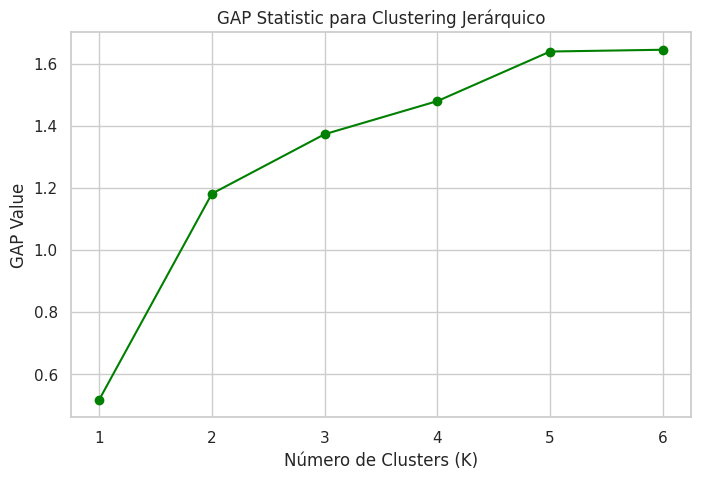

In [ ]:
import numpy as np

def calculate_wcss(X, labels):
    """
    Calcula la suma de cuadrados dentro de los clusters (WCSS) para un conjunto de datos y sus etiquetas de cluster.
    Esta es una métrica de dispersión utilizada para el GAP statistic en clustering jerárquico.
    """
    wcss = 0
    unique_labels = np.unique(labels)
    for label in unique_labels:
        cluster_points = X[labels == label]
        if cluster_points.shape[0] > 0:
            centroid = np.mean(cluster_points, axis=0)
            wcss += np.sum((cluster_points - centroid)**2)
    return wcss

def gap_statistic_hc(X, k_max=6, n_bootstraps=10, linkage_method='ward'):
    """
    Calcula el GAP statistic para el clustering jerárquico.
    """
    gaps = []
    for k in range(1, k_max + 1):
        # Calcular la dispersión (WCSS) para el dataset real
        if k == 1:
            # Para k=1, la dispersión es la varianza total con respecto a la media de todo el dataset
            disp_real = np.sum((X - np.mean(X, axis=0))**2)
        else:
            hc_real = AgglomerativeClustering(n_clusters=k, linkage=linkage_method).fit(X)
            disp_real = calculate_wcss(X, hc_real.labels_)

        # Calcular la dispersión (WCSS) para datasets de referencia nulos
        disp_null = []
        for _ in range(n_bootstraps):
            random_data = np.random.uniform(X.min(axis=0), X.max(axis=0), X.shape)
            if k == 1:
                disp_null.append(np.sum((random_data - np.mean(random_data, axis=0))**2))
            else:
                hc_null = AgglomerativeClustering(n_clusters=k, linkage=linkage_method).fit(random_data)
                disp_null.append(calculate_wcss(random_data, hc_null.labels_))

        # Calcular el GAP
        # Asegurarse de que las dispersiones no sean cero para evitar log(0)
        log_disp_null_mean = np.mean([np.log(d) if d > 0 else -np.inf for d in disp_null])
        log_disp_real = np.log(disp_real) if disp_real > 0 else -np.inf

        gap = log_disp_null_mean - log_disp_real
        gaps.append(gap)
    return gaps

# Calcular el GAP statistic para el clustering jerárquico
gaps_hc = gap_statistic_hc(X_scaled, k_max=6, n_bootstraps=10, linkage_method='ward')

# Visualizar el GAP statistic
plt.figure(figsize=(8, 5))
plt.plot(range(1, 7), gaps_hc, marker='o', color='green')
plt.title('GAP Statistic para Clustering Jerárquico')
plt.xlabel('Número de Clusters (K)')
plt.ylabel('GAP Value')
plt.grid(True)
plt.show()

>>**GAP Statistic para Clustering Jerárquico**

>>>Este gráfico muestra los valores del GAP Statistic para el Clustering Jerárquico. Similar al K-Means, el GAP Statistic ayuda a determinar el número óptimo de clusters comparando la dispersión del clustering con una distribución de referencia. Un GAP alto indica una estructura más marcada que la de un ruido aleatorio; como crece con K, el criterio útil es el punto de inflexión.

>>>Tal como era de esperar, observamos valores muy similares a los obtenidos con k-means. El GAP vuelve a crecer sin máximo (≈0.53, 1.19, 1.38, 1.48, 1.62, 1.64 para K=1 a 6), con el mayor salto entre K=1 y K=2 (+0.66). Por el criterio del codo, el número óptimo de clusters es 2.

## Conclusión Final del Trabajo Práctico

Este trabajo práctico abordó diversas técnicas de reducción de dimensionalidad y clustering aplicadas a un dataset de pingüinos, con el objetivo de identificar la estructura subyacente en los datos y el número óptimo de clusters.

### Reducción de Dimensionalidad

*   **PCA (Análisis de Componentes Principales):** La Regla de Kaiser sugirió un componente principal, mientras que el Gráfico de Codo (Scree Plot) y el porcentaje de varianza acumulada (por encima del 85%) indicaron que dos componentes principales son suficientes para capturar la mayor parte de la variabilidad de los datos. Visualmente, la proyección 2D de PCA mostró una buena separación entre las especies.
*   **Isomap:** Esta técnica no lineal también logró visualizar las especies de pingüinos en 2D, aunque en algunas configuraciones de `n_neighbors` se observaron advertencias sobre componentes desconectados, lo que sugiere que la conectividad del grafo de vecinos es crucial para su rendimiento. La separación de las especies fue consistente con PCA.
*   **t-SNE:** El análisis de t-SNE mostró una fuerte dependencia de sus parámetros, `perplexity` y `max_iter`. Se confirmó que valores adecuados para `max_iter` (al menos 250) son necesarios para una buena convergencia y que un `perplexity` de 30 fue efectivo para separar claramente las tres especies de pingüinos. Valores de `perplexity` menores a 30 o `max_iter` insuficientes resultaron en visualizaciones menos definidas.

En general, las tres técnicas de reducción de dimensionalidad fueron efectivas para visualizar la separación natural de las tres especies de pingüinos presentes en el dataset, siendo t-SNE particularmente potente para realzar estas agrupaciones.

### Análisis de Clustering

Se aplicaron dos algoritmos de clustering, K-Means y Clustering Jerárquico, evaluando el número óptimo de clusters mediante el Score de Silhouette y el GAP Statistic.

*   **K-Means:** El Score de Silhouette (máximo en K=2) y el GAP Statistic (mayor salto en K=2, sin un máximo claro) indicaron que **K=2** es el número óptimo de clusters para los datos preprocesados. Esto sugiere que, a pesar de tener tres especies en el dataset original, las características numéricas escaladas agrupan a los pingüinos en dos grandes conjuntos distintos. Visualmente, el gráfico 3D de K-Means con K=3 mostró una separación que intentó replicar las tres especies, pero las métricas sugieren que una división en dos es más natural para los atributos numéricos.
*   **Clustering Jerárquico:** Similar a K-Means, el análisis del Score de Silhouette y el GAP Statistic para el clustering jerárquico también apuntaron a **K=2** como el número óptimo de clusters. Esto refuerza la conclusión de que hay dos agrupaciones principales en los datos numéricos de los pingüinos.

### Conclusión General

El análisis de reducción de dimensionalidad confirmó la presencia de agrupaciones claras en el dataset de pingüinos, correspondientes a las especies. Sin embargo, las técnicas de clustering (K-Means y Jerárquico) evaluadas con el Score de Silhouette y el GAP Statistic sugirieron de forma consistente que el número óptimo de clusters basado exclusivamente en las características numéricas de los pingüinos es **K=2**. Esto podría indicar que, si bien hay tres especies biológicas, dos de ellas son muy similares en sus características biométricas o que una de las especies tiene características que la diferencian marcadamente de las otras dos combinadas.